运行约定：以本 Notebook 所在目录作为工作目录，从第一单元顺序运行。首个代码单元仅建立数据与输出目录。历史输出保留，不代表当前环境已验证。


In [1]:
import sys
from importlib.metadata import version
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
assert sys.version_info[:2] == (3, 12), "请选择项目的 Python 3.12 内核。"
assert version('torch').split("+")[0] == '2.14.1', "请选择项目锁定的运行环境。"
print("Python：", sys.version.split()[0])
print('torch' + "：", version('torch'))
print("运行模式：", '课堂默认训练参数')

Python： 3.12.12
torch： 2.14.1
运行模式： 课堂默认训练参数


In [2]:
from pathlib import Path
Path('../data').mkdir(parents=True, exist_ok=True)
Path('../outputs').mkdir(parents=True, exist_ok=True)


# LeNet-5 MNIST 手写数字识别分类器：教学规范版

本 Notebook 以经典 MNIST 手写数字识别为案例，完整走一遍深度学习图像分类项目的主线：

```text
问题定义 -> 数据理解 -> 图像预处理 -> 模型结构 -> 训练循环 -> 评估分析 -> 模型保存 -> 单图推理 -> 实验扩展
```

它不是单纯追求最高分，而是强调**教学清晰度、代码规范性、实验可复现性和工程可迁移性**。和传统机器学习 Titanic 案例相比，深度学习项目多了几个关键点：

- 输入不是表格特征，而是图像张量 `[N, C, H, W]`
- 特征不是手工设计，而是由卷积网络自动学习
- 训练过程不是一次 `fit()`，而是显式的 forward / loss / backward / step
- 评估不只看准确率，还要看混淆矩阵、错误样本和置信度
- 部署时要保证训练和推理的预处理完全一致

---

## 学习目标

完成本案例后，你应该能够：

1. 理解 MNIST 图像数据的基本结构和张量形状
2. 解释 LeNet-5 中卷积、池化、全连接层的作用
3. 写出规范的 PyTorch 训练循环和评估循环
4. 正确搭配 `logits + CrossEntropyLoss`
5. 保存和加载 `state_dict` / checkpoint
6. 对模型错误样本做基础分析
7. 将同样流程迁移到 CIFAR-10 或自定义图片分类任务

# 1. 项目设定与依赖导入

深度学习实验很容易受到随机初始化、数据打乱、设备差异影响。教学项目里建议先显式写清：

- 随机种子
- batch size / epoch / learning rate
- 数据目录和模型目录
- CPU / CUDA / Apple MPS 设备选择

这样学生在不同机器上运行时更容易定位问题。

In [3]:
from pathlib import Path
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image, ImageOps
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt


def set_seed(seed: int = 42):
    """尽量固定随机性，便于复现实验结果。"""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


SEED = 42
BATCH_SIZE = 64
TEST_BATCH_SIZE = 256
EPOCHS = 3
LEARNING_RATE = 1e-3
DATA_DIR = Path("../data")
MODEL_DIR = Path("../outputs/lenet_mnist_standard")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

set_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

PIN_MEMORY = device.type == "cuda"
NUM_WORKERS = 0  # Notebook 环境中设为 0 更稳，脚本训练时可按机器配置调大。

print(f"Using device: {device}")
print(f"PyTorch version: {torch.__version__}")

Using device: mps
PyTorch version: 2.14.1


# 2. 数据准备

MNIST 是图像分类入门最常用的数据集：

| 项目 | 说明 |
| --- | --- |
| 任务类型 | 10 分类 |
| 类别 | 数字 0 到 9 |
| 训练集 | 60,000 张 |
| 测试集 | 10,000 张 |
| 原始尺寸 | 28 x 28 |
| 颜色通道 | 1 通道灰度图 |

LeNet-5 的经典输入尺寸是 `32x32`，因此这里把 MNIST 从 `28x28` resize 到 `32x32`。

训练集可以做轻量数据增强，但要符合业务语义。**不要对 MNIST 使用水平翻转**，因为翻转可能改变数字含义。这里使用小角度旋转、平移和轻微缩放。

In [4]:
MNIST_MEAN = (0.1307,)
MNIST_STD = (0.3081,)

train_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.RandomAffine(
        degrees=10,
        translate=(0.08, 0.08),
        scale=(0.95, 1.05),
    ),
    transforms.ToTensor(),
    transforms.Normalize(MNIST_MEAN, MNIST_STD),
])

test_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(MNIST_MEAN, MNIST_STD),
])

# 下载并加载 MNIST 数据集
#
# datasets.MNIST 关键参数说明：
# - root: 数据集保存目录。本项目统一保存到 ../data
# - train=True: 加载训练集，包含 60,000 张图片
# - train=False: 加载测试集，包含 10,000 张图片
# - download=True: 如果 root 下已经有 MNIST 数据，会直接复用本地文件；如果没有，会自动下载
# - transform: 读取图片时应用的预处理流程
#
# 如果课堂环境不能联网，可以先把 MNIST 数据复制到 ../data/MNIST/raw，
# 然后把 download 改成 False。
train_set = datasets.MNIST(
    root=DATA_DIR,          # 保存到当前目录下的 ../data 文件夹
    train=True,             # 加载训练集
    download=True,          # 本地不存在时自动下载，本地已存在时直接复用
    transform=train_transform,  # 应用训练集预处理和数据增强
)

test_set = datasets.MNIST(
    root=DATA_DIR,          # 同样保存到 ../data 文件夹
    train=False,            # 加载测试集
    download=True,          # 本地不存在时自动下载，本地已存在时直接复用
    transform=test_transform,   # 应用测试集预处理，不做随机增强
)

train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

test_loader = DataLoader(
    test_set,
    batch_size=TEST_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
)

print(f"Train samples: {len(train_set)}")
print(f"Test samples:  {len(test_set)}")
print(f"Train batches: {len(train_loader)}")
print(f"Test batches:  {len(test_loader)}")

Train samples: 60000
Test samples:  10000
Train batches: 938
Test batches:  40


# 3. 图像 EDA：理解数据而不是直接训练

表格项目会看缺失值、字段分布、相关性；图像项目也需要 EDA，只是关注点不同：

- 每个类别样本数是否均衡
- 图像尺寸和通道是否一致
- 像素值范围是否符合预期
- 标准化前后的图像是否还能正确显示
- 数据增强是否改变了类别语义

下面先看类别分布。MNIST 类别基本均衡，所以 accuracy 是一个可用的主指标。

/var/folders/4f/lx3tlt3d6fz2bys8ct46fzxh0000gn/T/ipykernel_60875/3607095927.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  targets = torch.tensor(train_set.targets)


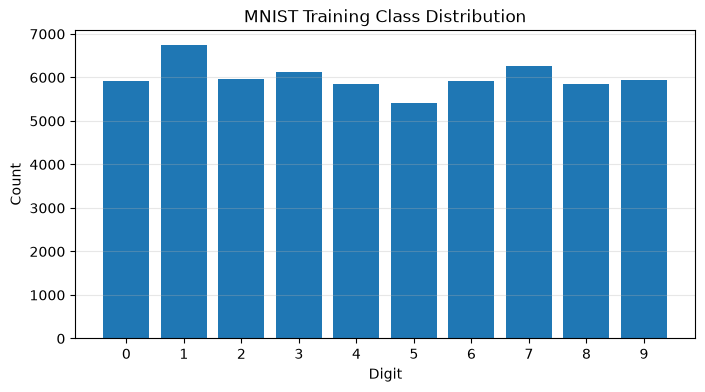

digit 0: 5923
digit 1: 6742
digit 2: 5958
digit 3: 6131
digit 4: 5842
digit 5: 5421
digit 6: 5918
digit 7: 6265
digit 8: 5851
digit 9: 5949


In [5]:
targets = torch.tensor(train_set.targets)
class_counts = torch.bincount(targets, minlength=10)

plt.figure(figsize=(8, 4))
plt.bar(range(10), class_counts.numpy())
plt.xticks(range(10))
plt.xlabel("Digit")
plt.ylabel("Count")
plt.title("MNIST Training Class Distribution")
plt.grid(axis="y", alpha=0.3)
plt.show()

for digit, count in enumerate(class_counts.tolist()):
    print(f"digit {digit}: {count}")

## 3.1 查看样本和张量形状

PyTorch 图像模型通常使用 `[N, C, H, W]`：

- `N`：batch size
- `C`：通道数，MNIST 是 1
- `H/W`：高度和宽度，这里是 32x32

理解这个形状非常关键，后续卷积层和全连接层的维度都依赖它。

Batch image shape: (64, 1, 32, 32)
Batch label shape: (64,)
Single image min/max after normalize: -0.4242129623889923 2.796030282974243


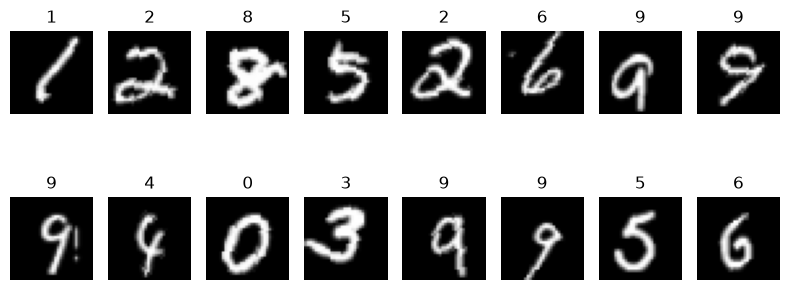

In [6]:
def denormalize(x: torch.Tensor) -> torch.Tensor:
    mean = torch.tensor(MNIST_MEAN).view(1, 1, 1)
    std = torch.tensor(MNIST_STD).view(1, 1, 1)
    return x.cpu() * std + mean

images, labels = next(iter(train_loader))
print("Batch image shape:", tuple(images.shape))
print("Batch label shape:", tuple(labels.shape))
print("Single image min/max after normalize:", float(images[0].min()), float(images[0].max()))

plt.figure(figsize=(8, 4))
for i in range(16):
    plt.subplot(2, 8, i + 1)
    plt.imshow(denormalize(images[i]).squeeze(), cmap="gray")
    plt.title(str(labels[i].item()))
    plt.axis("off")
plt.tight_layout()
plt.show()

# 4. LeNet-5 模型结构

LeNet-5 是早期卷积神经网络的代表结构，非常适合教学：

```text
Input 1x32x32
  -> Conv(1->6, 5x5) + ReLU        => 6x28x28
  -> MaxPool(2x2)                  => 6x14x14
  -> Conv(6->16, 5x5) + ReLU       => 16x10x10
  -> MaxPool(2x2)                  => 16x5x5
  -> Flatten                       => 400
  -> FC 400->120 -> 84 -> 10
```

注意：模型最后一层输出的是 10 个原始分数，也就是 logits。训练时使用 `CrossEntropyLoss`，它内部会完成 `log_softmax + NLLLoss`，因此模型里不要再手动写 `softmax`。

In [7]:
class LeNet5(nn.Module):
    def __init__(self, num_classes: int = 10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(6, 16, kernel_size=5),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Linear(16 * 5 * 5, 120),
            nn.ReLU(inplace=True),
            nn.Linear(120, 84),
            nn.ReLU(inplace=True),
            nn.Linear(84, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)


model = LeNet5().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(model)
print(f"Total params: {total_params:,}")
print(f"Trainable params: {trainable_params:,}")

LeNet5(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Linear(in_features=400, out_features=120, bias=True)
    (1): ReLU(inplace=True)
    (2): Linear(in_features=120, out_features=84, bias=True)
    (3): ReLU(inplace=True)
    (4): Linear(in_features=84, out_features=10, bias=True)
  )
)
Total params: 61,706
Trainable params: 61,706


## 4.1 用一次前向传播检查维度

正式训练前，建议先用一个 batch 跑一次 forward：

- 确认输入形状正确
- 确认输出形状是 `[batch_size, num_classes]`
- 确认 loss 可以正常计算

这一步能提前发现大部分维度错误。

In [8]:
sample_images, sample_labels = next(iter(train_loader))
sample_images = sample_images.to(device)
sample_labels = sample_labels.to(device)

with torch.no_grad():
    sample_logits = model(sample_images)
    sample_loss = criterion(sample_logits, sample_labels)

print("Input shape:", tuple(sample_images.shape))
print("Logits shape:", tuple(sample_logits.shape))
print("Sample loss:", float(sample_loss))
print("Predicted classes shape:", tuple(sample_logits.argmax(dim=1).shape))

Input shape: (64, 1, 32, 32)
Logits shape: (64, 10)
Sample loss: 2.3046483993530273
Predicted classes shape: (64,)


# 5. 训练循环：深度学习项目的核心

和 sklearn 的 `model.fit()` 不同，PyTorch 通常显式写训练循环：

1. `model.train()`：进入训练模式
2. forward：计算 logits
3. loss：计算损失
4. `loss.backward()`：反向传播
5. `optimizer.step()`：更新参数
6. 统计 epoch 平均 loss 和 accuracy

评估阶段要使用 `model.eval()` 和 `torch.no_grad()`，避免 Dropout/BatchNorm 行为错误，也避免无意义的梯度计算。

In [9]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += batch_size

    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        loss = criterion(logits, labels)

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += batch_size

    return running_loss / total, correct / total

# 6. 训练模型并保存最佳 checkpoint

这里保存两种文件：

| 文件 | 用途 |
| --- | --- |
| `best_lenet5_mnist_state_dict.pth` | 只保存模型参数，适合部署推理 |
| `best_lenet5_mnist_checkpoint.pth` | 保存模型参数、优化器、epoch、history，适合恢复训练 |

教学时建议优先讲 `state_dict`，因为它更稳定、更符合 PyTorch 推荐方式。

In [10]:
history = {
    "train_loss": [],
    "train_acc": [],
    "test_loss": [],
    "test_acc": [],
}

best_acc = 0.0
best_path = MODEL_DIR / "best_lenet5_mnist_state_dict.pth"
checkpoint_path = MODEL_DIR / "best_lenet5_mnist_checkpoint.pth"

for epoch in range(1, EPOCHS + 1):
    start = time.time()

    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    test_loss, test_acc = evaluate(model, test_loader, criterion, device)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_loss"].append(test_loss)
    history["test_acc"].append(test_acc)

    if test_acc > best_acc:
        best_acc = test_acc
        torch.save(model.state_dict(), best_path)
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_acc": best_acc,
            "history": history,
            "config": {
                "seed": SEED,
                "batch_size": BATCH_SIZE,
                "test_batch_size": TEST_BATCH_SIZE,
                "epochs": EPOCHS,
                "learning_rate": LEARNING_RATE,
                "mnist_mean": MNIST_MEAN,
                "mnist_std": MNIST_STD,
            },
        }, checkpoint_path)

    elapsed = time.time() - start
    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train_loss={train_loss:.4f}, train_acc={train_acc*100:.2f}% | "
        f"test_loss={test_loss:.4f}, test_acc={test_acc*100:.2f}% | "
        f"time={elapsed:.1f}s"
    )

print(f"Best test accuracy: {best_acc*100:.2f}%")
print(f"Best state_dict saved to: {best_path}")
print(f"Best checkpoint saved to: {checkpoint_path}")

Epoch 01/3 | train_loss=0.3399, train_acc=89.31% | test_loss=0.0634, test_acc=98.08% | time=12.9s


Epoch 02/3 | train_loss=0.1143, train_acc=96.43% | test_loss=0.0506, test_acc=98.32% | time=12.8s


Epoch 03/3 | train_loss=0.0867, train_acc=97.34% | test_loss=0.0503, test_acc=98.32% | time=12.9s
Best test accuracy: 98.32%
Best state_dict saved to: ../outputs/lenet_mnist_standard/best_lenet5_mnist_state_dict.pth
Best checkpoint saved to: ../outputs/lenet_mnist_standard/best_lenet5_mnist_checkpoint.pth


# 7. 训练过程可视化

训练曲线可以帮助判断模型状态：

- train loss 和 test loss 都下降：正常学习
- train loss 下降但 test loss 上升：可能过拟合
- loss 几乎不变：学习率、模型结构或数据预处理可能有问题
- train/test accuracy 差距很大：泛化能力不足

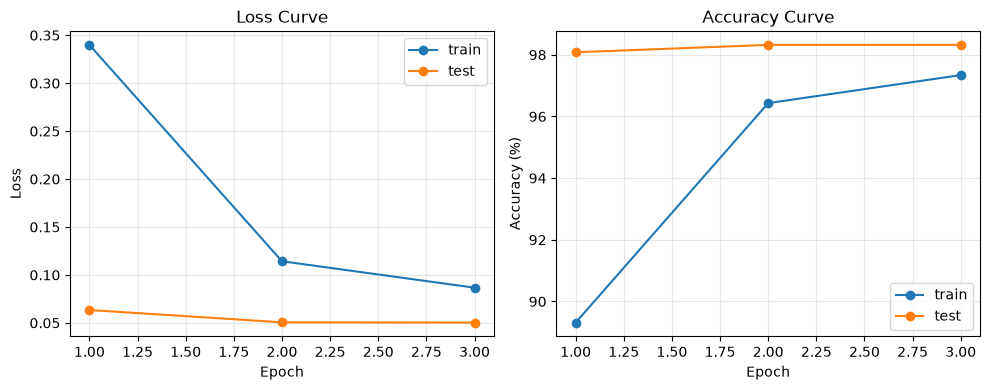

In [11]:
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], marker="o", label="train")
plt.plot(epochs, history["test_loss"], marker="o", label="test")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.grid(alpha=0.3)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, [v * 100 for v in history["train_acc"]], marker="o", label="train")
plt.plot(epochs, [v * 100 for v in history["test_acc"]], marker="o", label="test")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy Curve")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

# 8. 模型评估：混淆矩阵与错误样本

accuracy 只告诉我们总体表现，不告诉我们“错在哪里”。图像分类教学中，建议至少补充两类分析：

1. 混淆矩阵：哪些数字之间最容易混淆
2. 错误样本：模型错判时，图片本身是否模糊、歪斜或标注难辨

下面不依赖 sklearn，直接用 PyTorch 统计混淆矩阵。

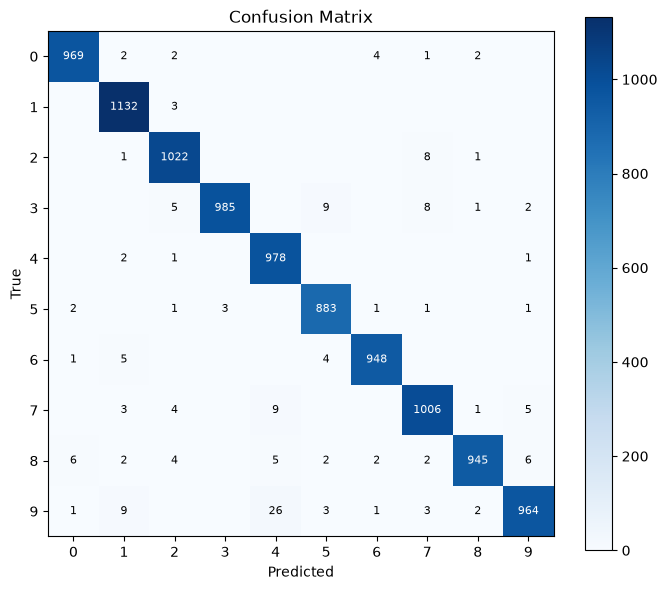

digit 0: 98.88%
digit 1: 99.74%
digit 2: 99.03%
digit 3: 97.52%
digit 4: 99.59%
digit 5: 98.99%
digit 6: 98.96%
digit 7: 97.86%
digit 8: 97.02%
digit 9: 95.54%


In [12]:
best_model = LeNet5().to(device)
best_model.load_state_dict(torch.load(best_path, map_location=device))
best_model.eval()

num_classes = 10
confusion = torch.zeros(num_classes, num_classes, dtype=torch.int64)
wrong_examples = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        logits = best_model(images)
        probs = torch.softmax(logits, dim=1)
        preds = logits.argmax(dim=1)

        for true_label, pred_label in zip(labels.cpu(), preds.cpu()):
            confusion[true_label, pred_label] += 1

        wrong_mask = preds != labels
        if wrong_mask.any() and len(wrong_examples) < 24:
            wrong_images = images[wrong_mask].cpu()
            wrong_labels = labels[wrong_mask].cpu()
            wrong_preds = preds[wrong_mask].cpu()
            wrong_probs = probs[wrong_mask].cpu()
            for img, true_label, pred_label, prob in zip(wrong_images, wrong_labels, wrong_preds, wrong_probs):
                wrong_examples.append((img, int(true_label), int(pred_label), float(prob[pred_label])))
                if len(wrong_examples) >= 24:
                    break

plt.figure(figsize=(7, 6))
plt.imshow(confusion.numpy(), cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(range(10))
plt.yticks(range(10))
plt.colorbar()

for i in range(10):
    for j in range(10):
        value = int(confusion[i, j])
        if value > 0:
            color = "white" if value > confusion.max() * 0.5 else "black"
            plt.text(j, i, str(value), ha="center", va="center", color=color, fontsize=8)

plt.tight_layout()
plt.show()

class_accuracy = confusion.diag() / confusion.sum(dim=1).clamp(min=1)
for digit, acc in enumerate(class_accuracy.tolist()):
    print(f"digit {digit}: {acc*100:.2f}%")

## 8.1 查看错误样本

错误样本分析是非常有教学价值的一步。它能帮助学生理解：模型不是“凭空犯错”，错误往往来自图像模糊、书写风格特殊、类别边界本身不清晰。

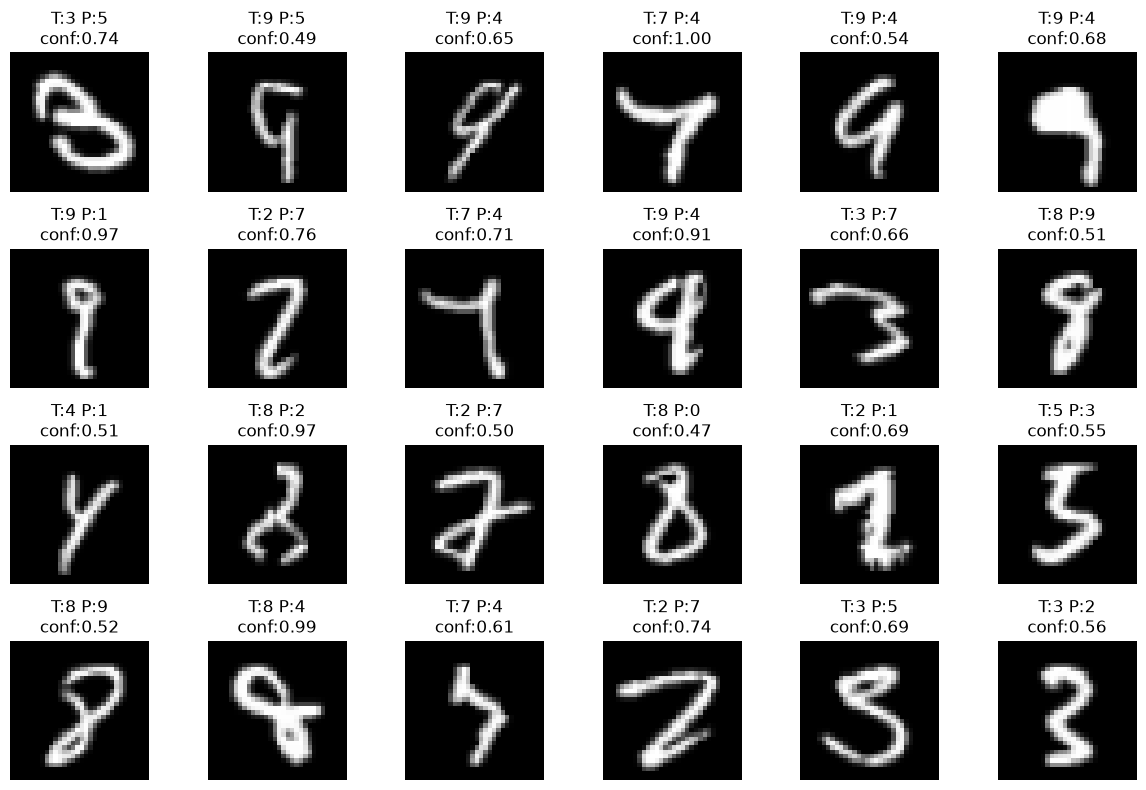

In [13]:
if wrong_examples:
    cols = 6
    rows = int(np.ceil(len(wrong_examples) / cols))
    plt.figure(figsize=(12, 2 * rows))

    for idx, (img, true_label, pred_label, confidence) in enumerate(wrong_examples):
        plt.subplot(rows, cols, idx + 1)
        plt.imshow(denormalize(img).squeeze(), cmap="gray")
        plt.title(f"T:{true_label} P:{pred_label}\nconf:{confidence:.2f}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No wrong examples collected.")

# 9. 保存、加载与部署视角

训练结束后，推荐的推理加载方式是：

1. 重新创建模型结构 `LeNet5()`
2. 加载 `state_dict`
3. `model.eval()`
4. 使用和测试集一致的预处理

这比直接 `torch.save(model)` 更稳定，因为它不依赖保存时的 Python 类路径。

In [14]:
loaded_model = LeNet5().to(device)
loaded_model.load_state_dict(torch.load(best_path, map_location=device))
loaded_model.eval()

loaded_loss, loaded_accuracy = evaluate(loaded_model, test_loader, criterion, device)
print(f"Loaded model test loss: {loaded_loss:.4f}")
print(f"Loaded model test accuracy: {loaded_accuracy*100:.2f}%")

Loaded model test loss: 0.0506
Loaded model test accuracy: 98.32%


# 10. 单张图片推理

外部图片与 MNIST 数据常有差异：

- MNIST 是黑底亮字
- 拍照或截图可能是白底黑字
- 图片大小、边距、笔画粗细都可能不同

下面的函数默认根据平均亮度自动判断是否需要反色，然后复用测试集预处理。这样可以减少训练和部署之间的预处理不一致。

In [15]:
def load_digit_image(image_path, auto_invert=True):
    image = Image.open(image_path).convert("L")

    if auto_invert and np.asarray(image).mean() > 127:
        image = ImageOps.invert(image)

    return test_transform(image).unsqueeze(0), image


@torch.no_grad()
def predict_digit(model, image_path, device, auto_invert=True):
    model.eval()
    image_tensor, raw_image = load_digit_image(image_path, auto_invert=auto_invert)
    image_tensor = image_tensor.to(device)
    logits = model(image_tensor)
    probabilities = torch.softmax(logits, dim=1).squeeze(0).cpu()
    pred = int(probabilities.argmax().item())
    confidence = float(probabilities[pred].item())
    return pred, confidence, probabilities, raw_image


image_path = Path("../assets/lenet-7.jpg")
if image_path.exists():
    pred, confidence, probabilities, raw_image = predict_digit(loaded_model, image_path, device)
    print(f"Prediction: {pred}")
    print(f"Confidence: {confidence:.4f}")
    print("Probabilities:", probabilities.numpy().round(4))

    plt.figure(figsize=(8, 3))
    plt.subplot(1, 2, 1)
    plt.imshow(raw_image, cmap="gray")
    plt.title("Input image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.bar(range(10), probabilities.numpy())
    plt.xticks(range(10))
    plt.ylim(0, 1)
    plt.title(f"Pred: {pred}, conf: {confidence:.2%}")
    plt.tight_layout()
    plt.show()
else:
    print(f"Image not found: {image_path}")

Image not found: ../assets/lenet-7.jpg


# 11. 实验扩展建议

教学时可以把这个 notebook 作为主线，然后安排几个渐进实验：

| 实验 | 修改点 | 观察目标 |
| --- | --- | --- |
| 去掉数据增强 | 删除 `RandomAffine` | 看测试集准确率和错误样本变化 |
| 调整 epoch | `EPOCHS = 1 / 3 / 5` | 理解训练轮数和收敛 |
| 调整学习率 | `1e-2 / 1e-3 / 1e-4` | 观察 loss 曲线是否震荡或过慢 |
| 换优化器 | Adam -> SGD | 比较优化器差异 |
| 加 Dropout | FC 层加入 Dropout | 理解正则化 |
| 迁移 CIFAR-10 | 输入通道 1 -> 3 | 理解彩色图像和更难任务 |

---

# 12. 项目总结

本项目完整覆盖了一个规范图像分类任务的核心流程：

```text
数据集加载
  -> 图像 EDA
  -> transform 预处理
  -> DataLoader 批量加载
  -> LeNet-5 模型定义
  -> logits + CrossEntropyLoss
  -> train/evaluate 循环
  -> checkpoint 保存
  -> 混淆矩阵和错误样本分析
  -> 单图推理
```

和表格机器学习项目相比，深度学习项目更强调：

- 张量形状
- 训练循环
- GPU/CPU 设备管理
- 数据增强
- 模型参数保存
- 推理预处理一致性

这个版本适合作为课堂教学主 notebook；原始 notebook 中的“简版”和“炫酷版”可以作为对照材料，而正式讲解建议围绕本规范版展开。

# 13. 附录：完整炫酷版训练系统


                  LeNet-5 Training System                   

System Information:
  - Date:        2026-10-18 15:41:03
  - Platform:    darwin
  - PyTorch:     2.14.1
  - CUDA:        Not Available ❌

Training Configuration:
  - Model:       LeNet-5
  - Optimizer:   Adam
  - LR:          0.001
  - Batch Size:  Train: 64, Test: 32
  - Epochs:       3
  - Save Dir:     ../outputs/

──────────────────────────────────────────────────
[INFO] Created directory: ../outputs/lenet_mnist
[INFO] Created directory: ../outputs/lenet_mnist/checkpoints
[INFO] Created directory: ../outputs/lenet_mnist/best_model
[INFO] Created directory: ../outputs/lenet_mnist/final_model

> Model Architecture
LeNet-5 Architecture:
  Layer                Output Shape         Param #   
  ──────────────────── ──────────────────── ──────────
  Conv1                6@28x28              156       
  ReLU                 6@28x28              0         
  MaxPool1             6@14x14              0         
  Conv2        

Batch  101/938 |█████---------------------------------------------| 10.8% Loss: 0.5143 | Acc:  61.91%

Batch  201/938 |██████████----------------------------------------| 21.4% Loss: 0.2184 | Acc:  73.59%

Batch  301/938 |████████████████----------------------------------| 32.1% Loss: 0.1273 | Acc:  79.16%

Batch  401/938 |█████████████████████-----------------------------| 42.8% Loss: 0.1607 | Acc:  82.51%

...



━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Epoch 3 Summary:
  Average Loss: 0.087383
  Training Accuracy: 97.33%
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

[INFO] Running validation...
Validating |--------------------------------------------------| 0.3% 

Validating |████████████████----------------------------------| 32.3% 

Validating |████████████████████████████████------------------| 64.2% 

Validating |████████████████████████████████████████████████--| 96.2% 


════════════════════════════════════════════════════════════
Validation Results
────────────────────────────────────────────────────────────
┌─────────────────────────┬──────────────────────────────┐
│         Metric         │            Value            │
├─────────────────────────┼──────────────────────────────┤
│Test Loss               │ 0.040644                    │
│Test Accuracy           │   98.72%                    │
│Correct/Total           │  9872/10000                    │
└─────────────────────────┴──────────────────────────────┘
════════════════════════════════════════════════════════════

[SUCCESS] Saved checkpoint for epoch 3 to ../outputs/lenet_mnist/checkpoints/lenet_mnist_epoch_003_checkpoint.pth
[INFO] Saved state_dict for epoch 3
[SUCCESS] Best model saved! Accuracy: 98.72% (epoch 3)
[INFO]    Model file: lenet_mnist_best_epoch_003_acc_98.72_state_dict.pth
[INFO]    Checkpoint file: lenet_mnist_best_epoch_003_acc_98.72_checkpoint.pth

> Epoch 3 Complete
Training c

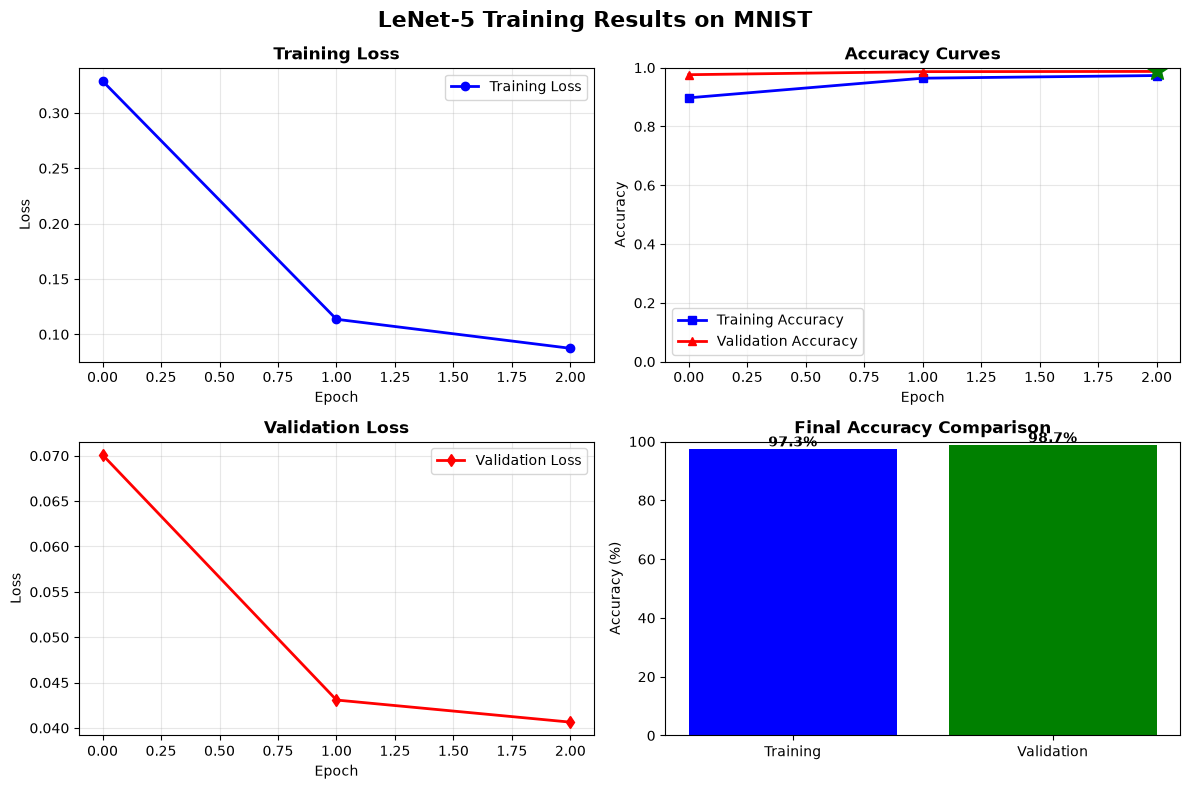

In [16]:
# ============================================================
# 1. Imports & Runtime Dependencies
# ============================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import time
import sys
import os
import numpy as np
from datetime import datetime
from torchvision import datasets, transforms
from PIL import Image, ImageOps
from matplotlib import pyplot as plt

# ============================================================
# 2. Console Style: 让训练日志更适合课堂展示
# ============================================================
class Colors:
    """ANSI颜色代码"""
    HEADER = '\033[95m'
    BLUE = '\033[94m'
    CYAN = '\033[96m'
    GREEN = '\033[92m'
    YELLOW = '\033[93m'
    RED = '\033[91m'
    BOLD = '\033[1m'
    UNDERLINE = '\033[4m'
    END = '\033[0m'
    GRAY = '\033[90m'
    ORANGE = '\033[33m'
    PURPLE = '\033[35m'

class PrintStyle:
    """打印格式样式"""
    @staticmethod
    def banner(text):
        """横幅样式"""
        width = 60
        print("\n" + "="*width)
        print(f"{Colors.PURPLE}{Colors.BOLD}{text:^{width}}{Colors.END}")
        print("="*width)
    
    @staticmethod
    def section_header(text):
        """章节标题"""
        print(f"\n{Colors.BLUE}{Colors.BOLD}> {text}{Colors.END}")
    
    @staticmethod
    def info(text):
        """信息样式"""
        print(f"{Colors.CYAN}[INFO]{Colors.END} {text}")
    
    @staticmethod
    def success(text):
        """成功样式"""
        print(f"{Colors.GREEN}[SUCCESS]{Colors.END} {text}")
    
    @staticmethod
    def warning(text):
        """警告样式"""
        print(f"{Colors.YELLOW}[WARNING]{Colors.END} {text}")
    
    @staticmethod
    def error(text):
        """错误样式"""
        print(f"{Colors.RED}[ERROR]{Colors.END} {text}")
    
    @staticmethod
    def progress_bar(iteration, total, prefix='', suffix='', length=50, fill='█'):
        """进度条"""
        percent = ("{0:.1f}").format(100 * (iteration / float(total)))
        filled_length = int(length * iteration // total)
        bar = fill * filled_length + '-' * (length - filled_length)
        
        sys.stdout.write(f'\r{prefix} |{Colors.GREEN}{bar}{Colors.END}| {percent}% {suffix}')
        sys.stdout.flush()
        
        if iteration == total:
            print()

# ============================================================
# 3. Model Saver: 管理 checkpoint、best model、final model 和训练历史
# ============================================================
class ModelSaver:
    """模型保存管理器"""
    def __init__(self, base_dir="../outputs", model_name="lenet_mnist"):
        """
        初始化模型保存器
        
        Args:
            base_dir: 模型保存的基础目录
            model_name: 模型名称前缀
        """
        self.base_dir = base_dir
        self.model_name = model_name
        self.models_dir = os.path.join(base_dir, model_name)
        self.best_accuracy = 0.0
        self.best_epoch = 0
        self.best_model_path = None
        
        # 创建模型保存目录
        self._create_directories()
        
    def _create_directories(self):
        """创建必要的目录结构"""
        dirs_to_create = [
            self.base_dir,
            self.models_dir,
            os.path.join(self.models_dir, "checkpoints"),
            os.path.join(self.models_dir, "best_model"),
            os.path.join(self.models_dir, "final_model"),
        ]
        
        for dir_path in dirs_to_create:
            if not os.path.exists(dir_path):
                os.makedirs(dir_path)
                PrintStyle.info(f"Created directory: {dir_path}")
            else:
                # 清空best_model目录
                if "best_model" in dir_path:
                    for file in os.listdir(dir_path):
                        file_path = os.path.join(dir_path, file)
                        try:
                            if os.path.isfile(file_path):
                                os.unlink(file_path)
                        except Exception as e:
                            PrintStyle.warning(f"Failed to delete {file_path}: {e}")
    
    def save_checkpoint(self, model, optimizer, epoch, train_loss, train_acc, val_loss, val_acc, is_best=False):
        """
        保存检查点（包含模型和元数据）
        
        Args:
            model: 要保存的模型
            optimizer: 优化器
            epoch: 当前epoch
            train_loss: 训练损失
            train_acc: 训练准确率
            val_loss: 验证损失
            val_acc: 验证准确率
            is_best: 是否为最佳模型
        """
        # 1. 保存模型检查点（包含元数据）
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'train_loss': train_loss,
            'train_accuracy': train_acc,
            'val_loss': val_loss,
            'val_accuracy': val_acc,
            'timestamp': datetime.now().strftime('%Y-%m-%d_%H-%M-%S'),
            'best_epoch': self.best_epoch,
            'best_accuracy': self.best_accuracy
        }
        
        checkpoint_path = os.path.join(
            self.models_dir, 
            "checkpoints", 
            f"{self.model_name}_epoch_{epoch:03d}_checkpoint.pth"
        )
        torch.save(checkpoint, checkpoint_path)
        PrintStyle.success(f"Saved checkpoint for epoch {epoch} to {checkpoint_path}")
        
        # 2. 保存模型参数（state_dict），比直接保存整个 Python 对象更稳
        model_path = os.path.join(
            self.models_dir,
            "checkpoints",
            f"{self.model_name}_epoch_{epoch:03d}_state_dict.pth"
        )
        torch.save(model.state_dict(), model_path)
        PrintStyle.info(f"Saved state_dict for epoch {epoch}")
        
        # 3. 如果是最佳模型，保存到best_model文件夹
        if is_best:
            # 清空best_model文件夹
            best_model_dir = os.path.join(self.models_dir, "best_model")
            for file in os.listdir(best_model_dir):
                file_path = os.path.join(best_model_dir, file)
                if os.path.isfile(file_path) and file.endswith('.pth'):
                    os.remove(file_path)
            
            # 保存最佳模型参数（state_dict）
            self.best_model_path = os.path.join(
                best_model_dir,
                f"{self.model_name}_best_epoch_{epoch:03d}_acc_{val_acc*100:.2f}_state_dict.pth"
            )
            torch.save(model.state_dict(), self.best_model_path)
            
            # 同时保存一个检查点版本（用于恢复训练）
            best_checkpoint_path = os.path.join(
                best_model_dir,
                f"{self.model_name}_best_epoch_{epoch:03d}_acc_{val_acc*100:.2f}_checkpoint.pth"
            )
            torch.save(checkpoint, best_checkpoint_path)
            
            PrintStyle.success(f"Best model saved! Accuracy: {val_acc*100:.2f}% (epoch {epoch})")
            PrintStyle.info(f"   Model file: {os.path.basename(self.best_model_path)}")
            PrintStyle.info(f"   Checkpoint file: {os.path.basename(best_checkpoint_path)}")
    
    def save_final_model(self, model, optimizer, train_losses, train_accuracies, val_losses, val_accuracies):
        """
        保存最终模型和训练历史
        
        Args:
            model: 最终模型
            optimizer: 优化器
            train_losses: 训练损失历史
            train_accuracies: 训练准确率历史
            val_losses: 验证损失历史
            val_accuracies: 验证准确率历史
        """
        # 保存最终模型参数（state_dict）
        final_model_path = os.path.join(
            self.models_dir,
            "final_model",
            f"{self.model_name}_final_state_dict.pth"
        )
        torch.save(model.state_dict(), final_model_path)
        
        # 保存最终检查点（包含训练历史）
        final_checkpoint = {
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'train_losses': train_losses,
            'train_accuracies': train_accuracies,
            'val_losses': val_losses,
            'val_accuracies': val_accuracies,
            'best_epoch': self.best_epoch,
            'best_accuracy': self.best_accuracy,
            'final_epoch': len(train_losses),
            'final_train_accuracy': train_accuracies[-1] if train_accuracies else 0,
            'final_val_accuracy': val_accuracies[-1] if val_accuracies else 0,
            'timestamp': datetime.now().strftime('%Y-%m-%d_%H-%M-%S')
        }
        
        final_checkpoint_path = os.path.join(
            self.models_dir,
            "final_model",
            f"{self.model_name}_final_checkpoint.pth"
        )
        torch.save(final_checkpoint, final_checkpoint_path)
        
        PrintStyle.success(f"Final model saved to {final_model_path}")
        PrintStyle.success(f"Final checkpoint saved to {final_checkpoint_path}")
        
        # 保存训练历史为CSV格式
        self._save_training_history(train_losses, train_accuracies, val_losses, val_accuracies)
        
        # 保存模型摘要
        self._save_model_summary(model, train_losses, train_accuracies, val_losses, val_accuracies)
    
    def _save_training_history(self, train_losses, train_accuracies, val_losses, val_accuracies):
        """保存训练历史为CSV格式"""
        import csv
        
        history_path = os.path.join(self.models_dir, "training_history.csv")
        
        with open(history_path, 'w', newline='') as csvfile:
            writer = csv.writer(csvfile)
            writer.writerow(['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy'])
            
            for epoch in range(len(train_losses)):
                writer.writerow([
                    epoch + 1,
                    train_losses[epoch],
                    train_accuracies[epoch],
                    val_losses[epoch],
                    val_accuracies[epoch]
                ])
        
        PrintStyle.info(f"Training history saved to {history_path}")
    
    def _save_model_summary(self, model, train_losses, train_accuracies, val_losses, val_accuracies):
        """保存模型训练摘要"""
        summary_path = os.path.join(self.models_dir, "training_summary.txt")
        
        with open(summary_path, 'w') as f:
            f.write("="*60 + "\n")
            f.write("LeNet-5 MNIST Training Summary\n")
            f.write("="*60 + "\n\n")
            
            f.write(f"Training Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
            f.write(f"Model Name: {self.model_name}\n")
            f.write(f"Total Epochs: {len(train_losses)}\n")
            f.write(f"Best Epoch: {self.best_epoch}\n")
            f.write(f"Best Validation Accuracy: {self.best_accuracy*100:.2f}%\n")
            f.write(f"Final Training Accuracy: {train_accuracies[-1]*100:.2f}%\n")
            f.write(f"Final Validation Accuracy: {val_accuracies[-1]*100:.2f}%\n\n")
            
            f.write("-"*60 + "\n")
            f.write("Training History:\n")
            f.write("-"*60 + "\n")
            f.write(f"{'Epoch':<6} {'Train Loss':<12} {'Train Acc':<12} {'Val Loss':<12} {'Val Acc':<12}\n")
            f.write("-"*60 + "\n")
            
            for epoch in range(len(train_losses)):
                f.write(f"{epoch+1:<6} "
                       f"{train_losses[epoch]:<12.6f} "
                       f"{train_accuracies[epoch]*100:<12.2f}% "
                       f"{val_losses[epoch]:<12.6f} "
                       f"{val_accuracies[epoch]*100:<12.2f}%\n")
        
        PrintStyle.info(f"Training summary saved to {summary_path}")
    
    def update_best_model(self, val_acc, epoch):
        """
        更新最佳模型信息
        
        Args:
            val_acc: 当前验证准确率
            epoch: 当前epoch
        
        Returns:
            bool: 如果当前模型是最佳模型则返回True
        """
        if val_acc > self.best_accuracy:
            self.best_accuracy = val_acc
            self.best_epoch = epoch
            return True
        return False
    
    def load_model(self, model_path, device=None):
        """加载 state_dict 并返回 LeNet 模型。"""
        if not os.path.exists(model_path):
            PrintStyle.error(f"Model file not found: {model_path}")
            return None

        try:
            device = device or torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
            model = LeNet().to(device)
            state_dict = torch.load(model_path, map_location=device)
            model.load_state_dict(state_dict)
            model.eval()
            PrintStyle.success(f"Loaded state_dict from {model_path}")
            return model
        except Exception as e:
            PrintStyle.error(f"Failed to load model: {e}")
            return None
    
    def load_checkpoint(self, checkpoint_path, model, optimizer=None):
        """
        加载检查点（用于恢复训练）
        
        Args:
            checkpoint_path: 检查点文件路径
            model: 要加载权重的模型
            optimizer: 要加载状态的优化器（可选）
        
        Returns:
            dict: 加载的检查点信息
        """
        if not os.path.exists(checkpoint_path):
            PrintStyle.error(f"Checkpoint not found: {checkpoint_path}")
            return None
        
        checkpoint = torch.load(checkpoint_path)
        
        if isinstance(checkpoint, dict) and 'model_state_dict' in checkpoint:
            model.load_state_dict(checkpoint['model_state_dict'])
            if optimizer is not None and 'optimizer_state_dict' in checkpoint:
                optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
            PrintStyle.success(f"Loaded checkpoint from epoch {checkpoint.get('epoch', 'unknown')}")
            return checkpoint
        else:
            PrintStyle.warning("Checkpoint format not recognized. Trying to load as model...")
            return checkpoint
    
    def get_best_model_info(self):
        """获取最佳模型文件信息"""
        best_model_dir = os.path.join(self.models_dir, "best_model")
        best_files = []
        
        if os.path.exists(best_model_dir):
            for file in os.listdir(best_model_dir):
                if file.endswith('.pth') and 'checkpoint' not in file:
                    best_files.append(os.path.join(best_model_dir, file))
        
        if self.best_model_path and os.path.exists(self.best_model_path):
            return self.best_model_path
        if best_files:
            best_files.sort(key=os.path.getmtime)
            return best_files[-1]
        return None

# ============================================================
# 4. Data Pipeline: 数据增强、标准化、Dataset 和 DataLoader
# ============================================================
# 定义训练集的数据预处理管道
pipline_train = transforms.Compose([
    transforms.Resize((32, 32)),
    # MNIST 不适合水平翻转，轻微旋转/平移/缩放更符合手写数字语义
    transforms.RandomAffine(degrees=10, translate=(0.08, 0.08), scale=(0.95, 1.05)),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# 定义测试集的数据预处理管道
pipline_test = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# 下载并加载MNIST数据集
train_set = datasets.MNIST(
    root="../data",
    train=True,
    download=True,
    transform=pipline_train
)

test_set = datasets.MNIST(
    root="../data",
    train=False,
    download=True,
    transform=pipline_test
)

# 创建数据加载器
trainloader = torch.utils.data.DataLoader(
    train_set,
    batch_size=64,
    shuffle=True,
    num_workers=0
)

testloader = torch.utils.data.DataLoader(
    test_set,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

# ============================================================
# 5. Model Definition: LeNet-5
# ============================================================
class LeNet(nn.Module):
    def __init__(self):
        super(LeNet, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, 5)
        self.relu = nn.ReLU()
        self.maxpool1 = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.maxpool2 = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)
 
    def forward(self, x):
        x = self.conv1(x)
        x = self.relu(x)
        x = self.maxpool1(x)
        x = self.conv2(x)
        x = self.maxpool2(x)
        x = x.view(-1, 16 * 5 * 5)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x  # 返回原始 logits，配合 F.cross_entropy 使用

# ============================================================
# 6. Train / Evaluate Loop
# ============================================================
def train_runner(model, device, trainloader, optimizer, epoch, total_epochs):
    """训练函数"""
    model.train()
    total = 0
    correct = 0.0
    total_batches = len(trainloader)
    running_loss = 0.0
    
    PrintStyle.section_header(f"Epoch {epoch}/{total_epochs}")
    
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = F.cross_entropy(outputs, labels)
        
        predict = outputs.argmax(dim=1)
        total += labels.size(0)
        correct += (predict == labels).sum().item()
        running_loss += loss.item()
        
        loss.backward()
        optimizer.step()
        
        # 进度条更新
        if i % 100 == 0 or i == total_batches - 1:
            accuracy = correct / total
            avg_loss = running_loss / (i + 1)
            prefix = f"{Colors.BOLD}Batch {i+1:4d}/{total_batches}{Colors.END}"
            suffix = f"Loss: {loss.item():.4f} | Acc: {100*accuracy:6.2f}%"
            PrintStyle.progress_bar(i+1, total_batches, prefix, suffix)
    
    accuracy = correct / total
    avg_loss = running_loss / total_batches
    
    # 显示epoch结果
    print(f"\n{Colors.GREEN}{'━'*50}{Colors.END}")
    print(f"{Colors.BOLD}Epoch {epoch} Summary:{Colors.END}")
    print(f"  {Colors.CYAN}Average Loss:{Colors.END} {Colors.BOLD}{avg_loss:.6f}{Colors.END}")
    print(f"  {Colors.GREEN}Training Accuracy:{Colors.END} {Colors.BOLD}{100*accuracy:.2f}%{Colors.END}")
    print(f"{Colors.GREEN}{'━'*50}{Colors.END}\n")
    
    return avg_loss, accuracy

def test_runner(model, device, testloader):
    """测试函数"""
    model.eval()
    correct = 0.0
    test_loss = 0.0
    total = 0
    
    PrintStyle.info("Running validation...")
    
    with torch.no_grad():
        for batch_idx, (data, label) in enumerate(testloader):
            data, label = data.to(device), label.to(device)
            output = model(data)
            test_loss += F.cross_entropy(output, label, reduction='sum').item()
            predict = output.argmax(dim=1)
            total += label.size(0)
            correct += (predict == label).sum().item()
            
            # 每100个batch显示一次进度
            if batch_idx % 100 == 0:
                PrintStyle.progress_bar(batch_idx + 1, len(testloader),
                                      f"{Colors.CYAN}Validating{Colors.END}", "")
    
    avg_loss = test_loss / total
    accuracy = correct / total
    
    # 结果表格
    print(f"\n{Colors.BLUE}{'═'*60}{Colors.END}")
    print(f"{Colors.BOLD}{Colors.PURPLE}Validation Results{Colors.END}")
    print(f"{Colors.BLUE}{'─'*60}{Colors.END}")
    
    print(f"{Colors.CYAN}┌{'─'*25}┬{'─'*30}┐{Colors.END}")
    print(f"{Colors.CYAN}│{Colors.END}{'Metric':^24}{Colors.CYAN}│{Colors.END}{'Value':^29}{Colors.CYAN}│{Colors.END}")
    print(f"{Colors.CYAN}├{'─'*25}┼{'─'*30}┤{Colors.END}")
    
    # 根据准确率显示不同颜色
    accuracy_color = Colors.GREEN if accuracy > 0.9 else Colors.YELLOW if accuracy > 0.8 else Colors.RED
    loss_color = Colors.RED if avg_loss > 0.5 else Colors.YELLOW if avg_loss > 0.1 else Colors.GREEN
    
    print(f"{Colors.CYAN}│{Colors.END}{'Test Loss':<24}{Colors.CYAN}│{Colors.END} {loss_color}{avg_loss:>8.6f}{Colors.END}{'':20}{Colors.CYAN}│{Colors.END}")
    print(f"{Colors.CYAN}│{Colors.END}{'Test Accuracy':<24}{Colors.CYAN}│{Colors.END} {accuracy_color}{accuracy*100:>7.2f}%{Colors.END}{'':20}{Colors.CYAN}│{Colors.END}")
    print(f"{Colors.CYAN}│{Colors.END}{'Correct/Total':<24}{Colors.CYAN}│{Colors.END} {correct:>5.0f}/{total:<5.0f}{'':20}{Colors.CYAN}│{Colors.END}")
    print(f"{Colors.CYAN}└{'─'*25}┴{'─'*30}┘{Colors.END}")
    print(f"{Colors.BLUE}{'═'*60}{Colors.END}\n")
    
    return avg_loss, accuracy

def print_system_info():
    """打印系统信息"""
    PrintStyle.banner("LeNet-5 Training System")
    
    print(f"\n{Colors.BOLD}System Information:{Colors.END}")
    print(f"  {Colors.CYAN}- Date:{Colors.END}        {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
    print(f"  {Colors.CYAN}- Platform:{Colors.END}    {sys.platform}")
    print(f"  {Colors.CYAN}- PyTorch:{Colors.END}     {torch.__version__}")
    print(f"  {Colors.CYAN}- CUDA:{Colors.END}        {'Available ✅' if torch.cuda.is_available() else 'Not Available ❌'}")
    
    if torch.cuda.is_available():
        print(f"  {Colors.CYAN}- GPU:{Colors.END}         {torch.cuda.get_device_name(0)}")
        print(f"  {Colors.CYAN}- CUDA Version:{Colors.END} {torch.version.cuda}")
    
    print(f"\n{Colors.BOLD}Training Configuration:{Colors.END}")
    print(f"  {Colors.GREEN}- Model:{Colors.END}       LeNet-5")
    print(f"  {Colors.GREEN}- Optimizer:{Colors.END}   Adam")
    print(f"  {Colors.GREEN}- LR:{Colors.END}          0.001")
    print(f"  {Colors.GREEN}- Batch Size:{Colors.END}  Train: 64, Test: 32")
    print(f"  {Colors.GREEN}- Epochs:{Colors.END}       3")
    print(f"  {Colors.GREEN}- Save Dir:{Colors.END}     ../outputs/")
    print(f"\n{Colors.YELLOW}{'─'*50}{Colors.END}")

def print_model_summary(model):
    """打印模型摘要"""
    PrintStyle.section_header("Model Architecture")
    
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    
    print(f"{Colors.CYAN}LeNet-5 Architecture:{Colors.END}")
    print(f"  {'Layer':<20} {'Output Shape':<20} {'Param #':<10}")
    print(f"  {'─'*20} {'─'*20} {'─'*10}")
    
    layers_info = [
        ("Conv1", "6@28x28", "156"),
        ("ReLU", "6@28x28", "0"),
        ("MaxPool1", "6@14x14", "0"),
        ("Conv2", "16@10x10", "2,416"),
        ("MaxPool2", "16@5x5", "0"),
        ("Flatten", "400", "0"),
        ("FC1", "120", "48,120"),
        ("FC2", "84", "10,164"),
        ("FC3", "10", "850")
    ]
    
    for layer, shape, params in layers_info:
        print(f"  {Colors.BLUE}{layer:<20}{Colors.END} {shape:<20} {params:<10}")
    
    print(f"\n{Colors.GREEN}Total params:{Colors.END} {total_params:,}")
    print(f"{Colors.GREEN}Trainable params:{Colors.END} {trainable_params:,}")
    print(f"{Colors.GREEN}Non-trainable params:{Colors.END} {total_params - trainable_params:,}")
    print(f"{Colors.YELLOW}{'─'*50}{Colors.END}")


# ============================================================
# 7. Prediction: 加载最佳模型并预测单张图片
# ============================================================
def preprocess_digit_image(image_path, auto_invert=True):
    """读取外部手写数字图片，并转换成 LeNet 需要的 [1, 1, 32, 32] 张量。"""
    image = Image.open(image_path).convert("L")

    # MNIST 通常是黑底亮字；如果外部图片是白底黑字，自动反色。
    if auto_invert and np.asarray(image).mean() > 127:
        image = ImageOps.invert(image)

    transform = transforms.Compose([
        transforms.Resize((32, 32)),
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,)),
    ])
    return transform(image).unsqueeze(0), image


@torch.no_grad()
def predict_digit_image(model_path, image_path="../assets/lenet-7.jpg", device=None, auto_invert=True, show_plot=True):
    """使用保存的 state_dict 对单张手写数字图片做预测。"""
    if not os.path.exists(model_path):
        PrintStyle.error(f"Model state_dict not found: {model_path}")
        return None
    if not os.path.exists(image_path):
        PrintStyle.error(f"Image not found: {image_path}")
        return None

    device = device or torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")

    model = LeNet().to(device)
    state_dict = torch.load(model_path, map_location=device)
    model.load_state_dict(state_dict)
    model.eval()

    image_tensor, display_image = preprocess_digit_image(image_path, auto_invert=auto_invert)
    image_tensor = image_tensor.to(device)

    logits = model(image_tensor)
    probabilities = torch.softmax(logits, dim=1).squeeze(0).cpu()
    pred = int(probabilities.argmax().item())
    confidence = float(probabilities[pred].item())

    PrintStyle.section_header("Single Image Prediction")
    PrintStyle.info(f"Image: {image_path}")
    PrintStyle.info(f"Prediction: {pred}")
    PrintStyle.info(f"Confidence: {confidence:.4f}")
    PrintStyle.info(f"Probabilities: {probabilities.numpy().round(4)}")

    if show_plot:
        plt.figure(figsize=(8, 3))
        plt.subplot(1, 2, 1)
        plt.imshow(display_image, cmap="gray")
        plt.title("Input image")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.bar(range(10), probabilities.numpy())
        plt.xticks(range(10))
        plt.ylim(0, 1)
        plt.title(f"Pred: {pred}, conf: {confidence:.2%}")
        plt.tight_layout()
        plt.show()

    return pred, confidence, probabilities


# ============================================================
# 8. Main Entry: 串联配置、训练、验证、保存、预测和可视化
# ============================================================
def main():
    # Notebook 教学中保留历史输出更利于讲解；如在终端脚本运行，可手动启用清屏。
    # os.system('cls' if os.name == 'nt' else 'clear')
    
    # 打印系统信息
    print_system_info()
    
    # 创建模型保存器
    model_saver = ModelSaver(base_dir="../outputs", model_name="lenet_mnist")
    
    # 创建模型
    device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    model = LeNet().to(device)
    
    # 打印模型信息
    print_model_summary(model)
    
    # 定义优化器
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    
    # 训练参数
    epochs = 3
    train_losses = []
    train_accuracies = []
    val_losses = []
    val_accuracies = []
    
    PrintStyle.banner("Starting Training")
    
    for epoch in range(1, epochs + 1):
        epoch_start_time = time.time()
        
        # 训练
        train_loss, train_acc = train_runner(model, device, trainloader, optimizer, epoch, epochs)
        train_losses.append(train_loss)
        train_accuracies.append(train_acc)
        
        # 测试
        val_loss, val_acc = test_runner(model, device, testloader)
        val_losses.append(val_loss)
        val_accuracies.append(val_acc)
        
        # 更新最佳模型并检查是否为最佳
        is_best = model_saver.update_best_model(val_acc, epoch)
        
        # 保存检查点
        model_saver.save_checkpoint(
            model=model,
            optimizer=optimizer,
            epoch=epoch,
            train_loss=train_loss,
            train_acc=train_acc,
            val_loss=val_loss,
            val_acc=val_acc,
            is_best=is_best
        )
        
        epoch_time = time.time() - epoch_start_time
        
        # 打印epoch总结
        PrintStyle.section_header(f"Epoch {epoch} Complete")
        print(f"{Colors.GREEN}Training completed in {epoch_time:.2f} seconds{Colors.END}")
        print(f"{Colors.CYAN}Training Acc: {train_acc*100:.2f}% | Validation Acc: {val_acc*100:.2f}%{Colors.END}")
        
        if is_best:
            print(f"{Colors.GREEN}New best model! Accuracy: {val_acc*100:.2f}%{Colors.END}")
        
        if val_acc > 0.95:
            PrintStyle.success("Excellent accuracy achieved!")
        elif val_acc > 0.9:
            PrintStyle.success("Great performance!")
        elif val_acc > 0.85:
            PrintStyle.info("Good performance. Keep going.")
        else:
            PrintStyle.warning("Accuracy can be improved. Try adjusting hyperparameters.")
    
    # 保存最终模型
    model_saver.save_final_model(model, optimizer, train_losses, train_accuracies, val_losses, val_accuracies)
    
    # 最终总结
    PrintStyle.banner("Training Complete!")
    
    best_epoch = model_saver.best_epoch
    best_acc = model_saver.best_accuracy * 100
    
    print(f"\n{Colors.BOLD}Training Summary:{Colors.END}")
    print(f"  {Colors.GREEN}● Total Epochs:{Colors.END}        {epochs}")
    print(f"  {Colors.GREEN}● Best Epoch:{Colors.END}          {best_epoch}")
    print(f"  {Colors.GREEN}● Best Validation Acc:{Colors.END}  {best_acc:.2f}%")
    print(f"  {Colors.GREEN}● Final Training Acc:{Colors.END}   {train_accuracies[-1]*100:.2f}%")
    print(f"  {Colors.GREEN}● Final Validation Acc:{Colors.END} {val_accuracies[-1]*100:.2f}%")
    
    # 打印模型保存信息
    PrintStyle.section_header("Model Files Saved")
    
    # 获取最佳模型文件
    best_model_path = model_saver.get_best_model_info()
    if best_model_path and os.path.exists(best_model_path):
        filename = os.path.basename(best_model_path)
        print(f"{Colors.GREEN}Best Model File:{Colors.END}   {filename}")
        print(f"  - Path: {best_model_path}")
        print(f"  - Load with: model = LeNet(); model.load_state_dict(torch.load(path))")
    else:
        print(f"{Colors.YELLOW}Best model not found{Colors.END}")

    # 训练结束后，顺手演示一次单张图片预测。没有示例图时会自动跳过。
    sample_image_path = "../assets/lenet-7.jpg"
    if best_model_path and os.path.exists(sample_image_path):
        predict_digit_image(best_model_path, sample_image_path, device=device, show_plot=True)
    elif not os.path.exists(sample_image_path):
        PrintStyle.warning(f"Prediction demo skipped. Image not found: {sample_image_path}")
    
    print(f"\n{Colors.CYAN}Directory Structure:{Colors.END}")
    print(f"  {Colors.BLUE}● checkpoints/{Colors.END}")
    print(f"    - {Colors.GRAY}lenet_mnist_epoch_XXX_state_dict.pth{Colors.END} (直接可用的模型文件)")
    print(f"    - {Colors.GRAY}lenet_mnist_epoch_XXX_checkpoint.pth{Colors.END} (包含训练信息的检查点)")
    print(f"  {Colors.BLUE}● best_model/{Colors.END}")
    print(f"    - {Colors.GRAY}lenet_mnist_best_epoch_XXX_acc_XX.XX.pth{Colors.END} (最佳模型参数，推荐 load_state_dict 加载)")
    print(f"  {Colors.BLUE}● final_model/{Colors.END}")
    print(f"    - {Colors.GRAY}lenet_mnist_final_state_dict.pth{Colors.END} (最终模型参数)")
    print(f"  {Colors.BLUE}● training_history.csv{Colors.END}")
    print(f"    - 训练历史数据")
    print(f"  {Colors.BLUE}● training_summary.txt{Colors.END}")
    print(f"    - 训练摘要")
    
    if best_acc > 99:
        print(f"\n{Colors.GREEN}{Colors.BOLD}Outstanding performance. Model is ready for deployment.{Colors.END}")
    elif best_acc > 98:
        print(f"\n{Colors.GREEN}{Colors.BOLD}Excellent results. Model performance is outstanding.{Colors.END}")
    elif best_acc > 97:
        print(f"\n{Colors.GREEN}{Colors.BOLD}Great job. Model is performing very well.{Colors.END}")
    elif best_acc > 95:
        print(f"\n{Colors.YELLOW}{Colors.BOLD}Good performance. Model is learning well.{Colors.END}")
    else:
        print(f"\n{Colors.RED}{Colors.BOLD}Consider training for more epochs or adjusting hyperparameters.{Colors.END}")
    
    # 显示最佳模型的使用方法
    PrintStyle.section_header("How to Load and Use the Model")
    if best_model_path:
        print(f"{Colors.CYAN}Method 1 - Direct loading (recommended):{Colors.END}")
        print(f"{Colors.GRAY}import torch{Colors.END}")
        print(f"{Colors.GRAY}import cv2{Colors.END}")
        print(f"{Colors.GRAY}from torchvision import transforms{Colors.END}")
        print(f"\n{Colors.GRAY}# Load model directly{Colors.END}")
        print(f"{Colors.GRAY}model = torch.load('{best_model_path}'){Colors.END}")
        print(f"{Colors.GRAY}model.eval(){Colors.END}")
        print(f"\n{Colors.GRAY}# Use the model for inference{Colors.END}")
        print(f"{Colors.GRAY}# ... your inference code ...{Colors.END}")
        
        print(f"\n{Colors.CYAN}Method 2 - Load checkpoint (for resuming training):{Colors.END}")
        print(f"{Colors.GRAY}checkpoint = torch.load('{best_model_path.replace('.pth', '_checkpoint.pth') if os.path.exists(best_model_path.replace('.pth', '_checkpoint.pth')) else best_model_path}'){Colors.END}")
        print(f"{Colors.GRAY}model = LeNet()  # Create new model instance{Colors.END}")
        print(f"{Colors.GRAY}model.load_state_dict(checkpoint['model_state_dict']){Colors.END}")
    
    print(f"\n{Colors.PURPLE}{'='*50}{Colors.END}")
    print(f"{Colors.BOLD}Training session completed at: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}{Colors.END}")
    print(f"{Colors.PURPLE}{'='*50}{Colors.END}")
    
    # 绘制训练曲线
    try:
        import matplotlib.pyplot as plt
        
        fig, axes = plt.subplots(2, 2, figsize=(12, 8))
        
        # 训练损失
        axes[0, 0].plot(train_losses, 'b-', linewidth=2, marker='o', label='Training Loss')
        axes[0, 0].set_title('Training Loss', fontsize=12, fontweight='bold')
        axes[0, 0].set_xlabel('Epoch')
        axes[0, 0].set_ylabel('Loss')
        axes[0, 0].grid(True, alpha=0.3)
        axes[0, 0].legend()
        
        # 准确率曲线
        axes[0, 1].plot(train_accuracies, 'b-', linewidth=2, marker='s', label='Training Accuracy')
        axes[0, 1].plot(val_accuracies, 'r-', linewidth=2, marker='^', label='Validation Accuracy')
        axes[0, 1].set_title('Accuracy Curves', fontsize=12, fontweight='bold')
        axes[0, 1].set_xlabel('Epoch')
        axes[0, 1].set_ylabel('Accuracy')
        axes[0, 1].set_ylim(0, 1.0)
        axes[0, 1].grid(True, alpha=0.3)
        axes[0, 1].legend()
        
        # 标记最佳准确率
        best_idx = best_epoch - 1
        if 0 <= best_idx < len(val_accuracies):
            axes[0, 1].plot(best_idx, val_accuracies[best_idx], 'g*', markersize=15, 
                          label=f'Best: {val_accuracies[best_idx]*100:.1f}%')
        
        # 验证损失
        axes[1, 0].plot(val_losses, 'r-', linewidth=2, marker='d', label='Validation Loss')
        axes[1, 0].set_title('Validation Loss', fontsize=12, fontweight='bold')
        axes[1, 0].set_xlabel('Epoch')
        axes[1, 0].set_ylabel('Loss')
        axes[1, 0].grid(True, alpha=0.3)
        axes[1, 0].legend()
        
        # 最终准确率对比
        axes[1, 1].bar(['Training', 'Validation'], 
                      [train_accuracies[-1]*100, val_accuracies[-1]*100], 
                      color=['blue', 'green'])
        axes[1, 1].set_title('Final Accuracy Comparison', fontsize=12, fontweight='bold')
        axes[1, 1].set_ylabel('Accuracy (%)')
        axes[1, 1].set_ylim(0, 100)
        axes[1, 1].text(0, train_accuracies[-1]*100 + 1, f'{train_accuracies[-1]*100:.1f}%', 
                       ha='center', fontweight='bold')
        axes[1, 1].text(1, val_accuracies[-1]*100 + 1, f'{val_accuracies[-1]*100:.1f}%', 
                       ha='center', fontweight='bold')
        
        plt.suptitle('LeNet-5 Training Results on MNIST', fontsize=16, fontweight='bold')
        plt.tight_layout()
        plt.show()
        
    except ImportError:
        PrintStyle.warning("matplotlib not installed. Skipping plots.")

if __name__ == "__main__":
    main()